# Downloading Libraries


In [1]:
! pip install nltk
! pip install vaderSentiment
! pip install pytrends
! pip install textblob
! pip install wordcloud
! pip install gensim
! pip install seaborn
! pip install TextBlob
! pip install joblib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached vaderSentiment-3.3.2-py2.py3-none-any.whl.metadata (572 bytes)
Using cached vaderSentiment-3.3.2-py2.py3-none-any.whl (125 kB)



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached pytrends-4.9.2-py3-none-any.whl.metadata (13 kB)
Using cached pytrends-4.9.2-py3-none-any.whl (15 kB)
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.0 MB ? eta -:--:--
   ------------------ --------------------- 1.8/4.0 MB 5.7 MB/s eta 0:00:01
   ---------------------------------- ----- 3.4/4.0 MB 8.0 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 6.5 MB/s  0:00:01

   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 0/2 [lxml]
   ---------------------------------------- 2/2 [pytrends]




[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


...

  Using cached gensim-4.4.0-cp313-cp313-win_amd64.whl.metadata (8.6 kB)
  Using cached smart_open-8.0.1-py3-none-any.whl.metadata (24 kB)
Using cached gensim-4.4.0-cp313-cp313-win_amd64.whl (24.4 MB)
Using cached smart_open-8.0.1-py3-none-any.whl (73 kB)

   ---------------------------------------- 0/2 [smart_open]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]
   -------------------- ------------------- 1/2 [gensim]


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Importing Libraries


In [2]:
import nltk
import logging
import numpy as np
import pandas as pd
import seaborn as sns
from textblob import TextBlob
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer


from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, GradientBoostingClassifier

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

import joblib
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [3]:
# Download NLTK resources (if not already downloaded)
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('wordnet', quiet=True)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Palan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Palan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Palan\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

# Importing Dataset

In [4]:
df = pd.read_csv('../data/cleaned/reviews.csv')
df

,date,reviewer_name,comments,cleaned_comments,polarity,sentiment
0,2025-11-30,Lara,Leider haben wir Laura nicht persönlich angetr...,leider haben wir laura nicht persönlich angetr...,-0.700000,negative
1,2022-11-28,Axel,Sehr kleines und sauberes Zimmer in ansprechen...,sehr klein und sauber zimmer ansprechend lage ...,-0.700000,negative
2,2023-10-30,Arno,Die Wohnung hate eine gute Lage. Mit dem Bus 1...,die wohnung hate ein gute lage mit dem bu min ...,-0.800000,negative
3,2017-11-25,María Eugenia,La zona del apartamento es genial si quieres p...,la zona del apartamento e genial si quier pasa...,-0.600000,negative
4,2025-06-21,Yigit Ertan,Wir waren für fünf Nächte bei Emre zu Besuch. ...,wir waren für fünf nächte bei emr zu besuch au...,-0.700000,negative
...,...,...,...,...,...,...
19768,2019-07-01,Debjani,My stay at Paul's was one of the best I've had...,stay paul one best ive airbnb room spaciou bri...,0.564286,positive
19769,2017-01-19,Won,One of the best overall AirBnB experiences tha...,one best overal airbnb experi far lateef famil...,0.444444,positive
19770,2026-05-30,Melody,"Very easy check in, good location close to bus...",easi check good locat close bustub took min ce...,0.373333,positive
19771,2018-08-19,Raha,"Siwen’s place is beautiful, clean, and in a gr...",siwen’ place beauti clean great locat also cat...,0.500000,positive


# Date Preprocessing


In [5]:
df.isnull().sum()

date                0
reviewer_name       0
comments            0
cleaned_comments    0
polarity            0
sentiment           0
dtype: int64

In [6]:
# Dropping the null values
df.dropna(inplace=True)
df.isnull().sum()

date                0
reviewer_name       0
comments            0
cleaned_comments    0
polarity            0
sentiment           0
dtype: int64

# Exploratory Data Analysis


In [7]:
reviewer_freq = df['reviewer_name'].value_counts()
print(reviewer_freq)

reviewer_name
David          119
Michael        116
Laura          113
Daniel         107
Sarah          102
              ... 
Jean-Claude      1
Debjani          1
Won              1
Melody           1
Raha             1
Name: count, Length: 7554, dtype: int64


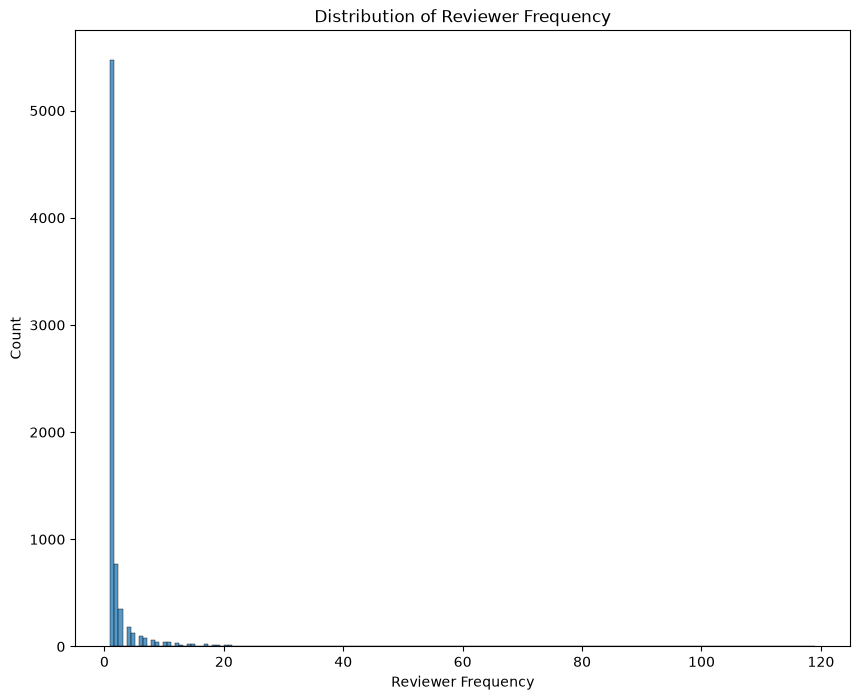

In [8]:
# plot the distribution of reviewer frequency using seaborn
plt.figure(figsize=(10, 8))
sns.histplot(reviewer_freq, kde=False)
plt.title('Distribution of Reviewer Frequency')
plt.xlabel('Reviewer Frequency')
plt.ylabel('Count')
plt.show()

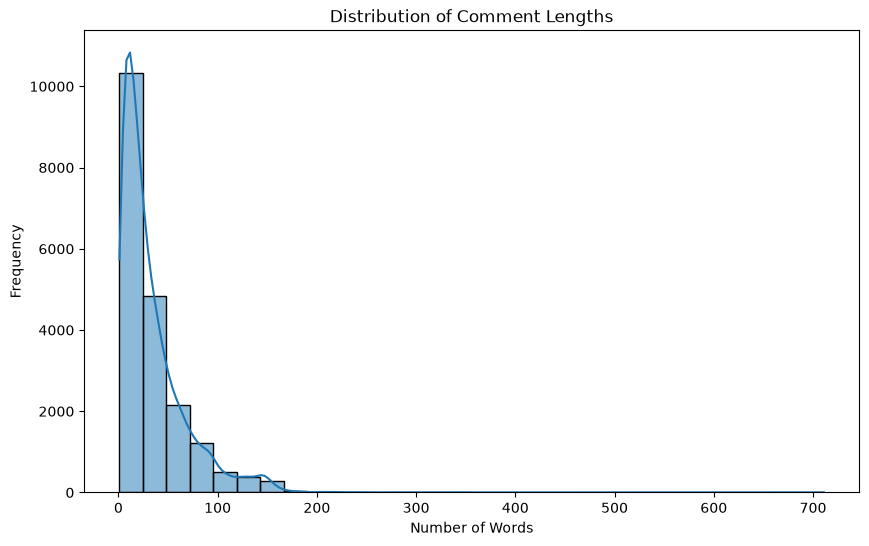

In [9]:
df['comment_length'] = df['cleaned_comments'].apply(lambda x: len(x.split()))
plt.figure(figsize=(10, 6))
sns.histplot(df['comment_length'], bins=30, kde=True)
plt.title('Distribution of Comment Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

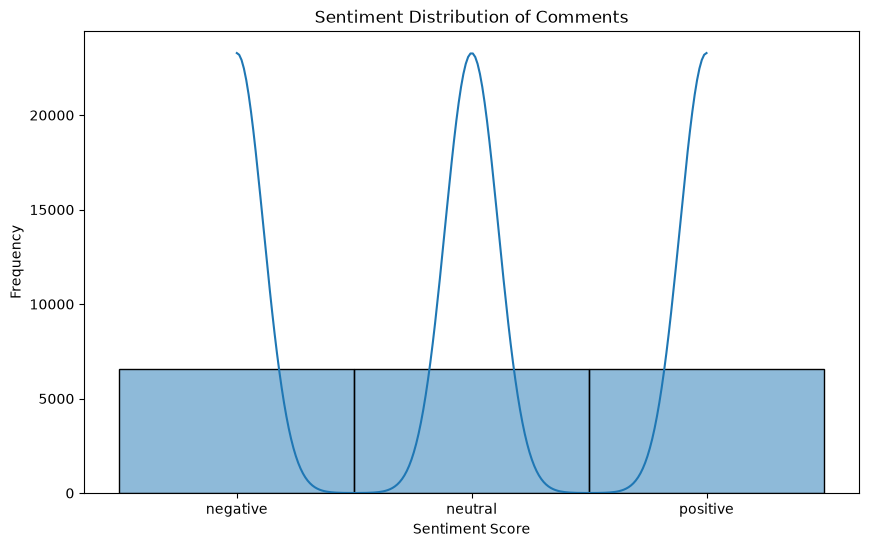

In [10]:
# Visualizing Sentiment Distribution
plt.figure(figsize=(10, 6))
sns.histplot(df['sentiment'], bins=30, kde=True)
plt.title('Sentiment Distribution of Comments')
plt.xlabel('Sentiment Score')
plt.ylabel('Frequency')
plt.show()

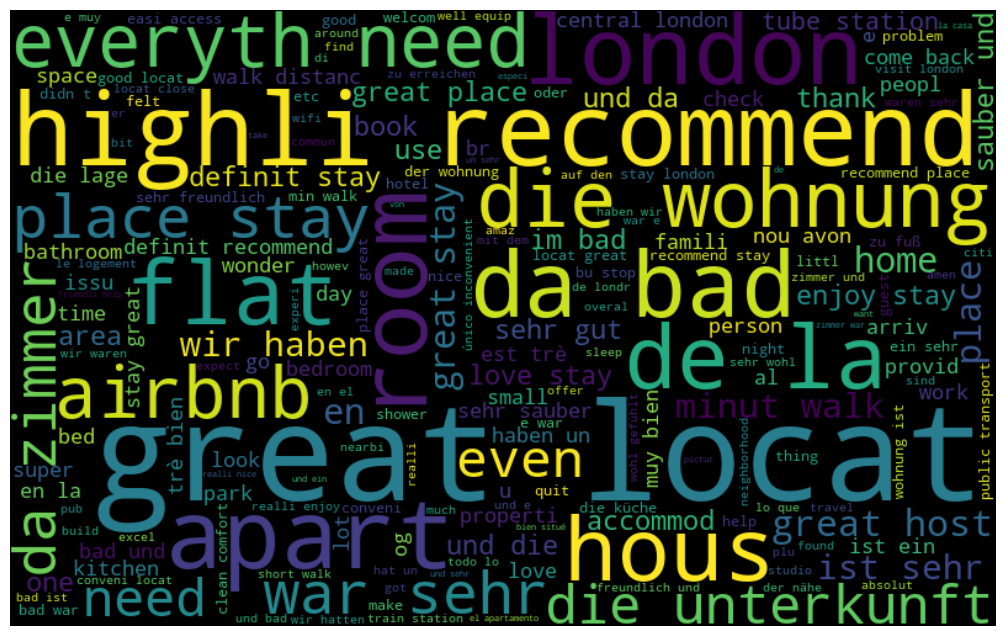

In [11]:
# Word Frequency Analysis
all_words = ' '.join([text for text in df['cleaned_comments']])
wordcloud = WordCloud(width=800, height=500, random_state=21,
                      max_font_size=110).generate(all_words)

plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis('off')
plt.show()

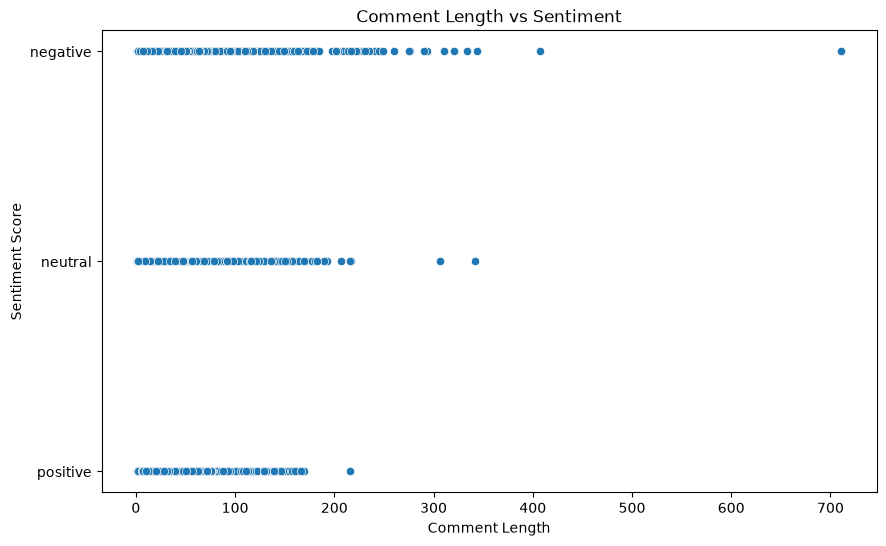

In [12]:
# Comment Length vs Sentiment
plt.figure(figsize=(10, 6))
sns.scatterplot(x='comment_length', y='sentiment', data=df)
plt.title('Comment Length vs Sentiment')
plt.xlabel('Comment Length')
plt.ylabel('Sentiment Score')
plt.show()

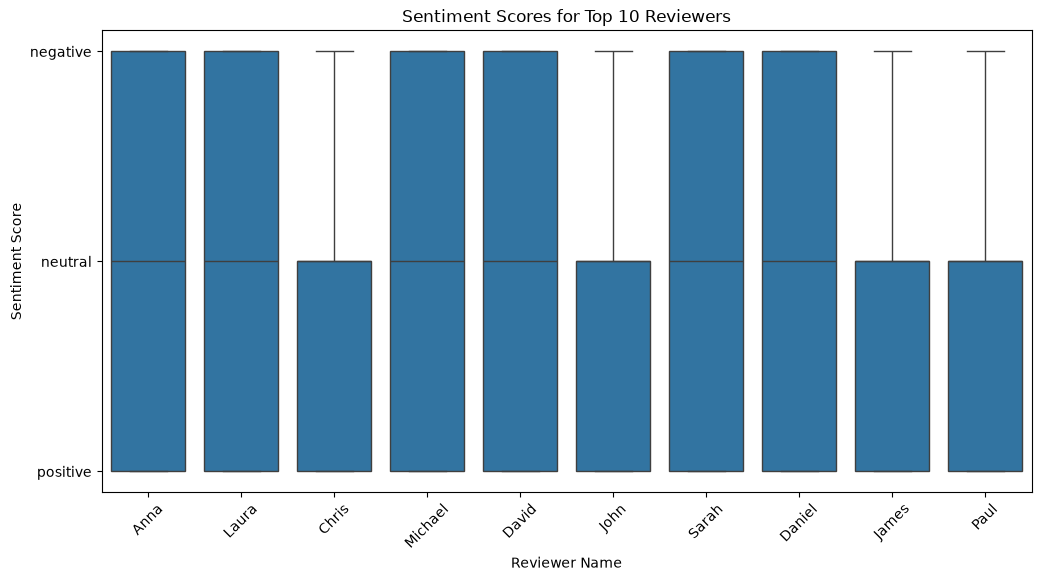

In [13]:
# Reviewer Frequency and Sentiment
# Top 10 reviewers
top_reviewers = df['reviewer_name'].value_counts().head(10).index
top_reviewers_df = df[df['reviewer_name'].isin(top_reviewers)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='reviewer_name', y='sentiment', data=top_reviewers_df)
plt.xticks(rotation=45)
plt.title('Sentiment Scores for Top 10 Reviewers')
plt.xlabel('Reviewer Name')
plt.ylabel('Sentiment Score')
plt.show()

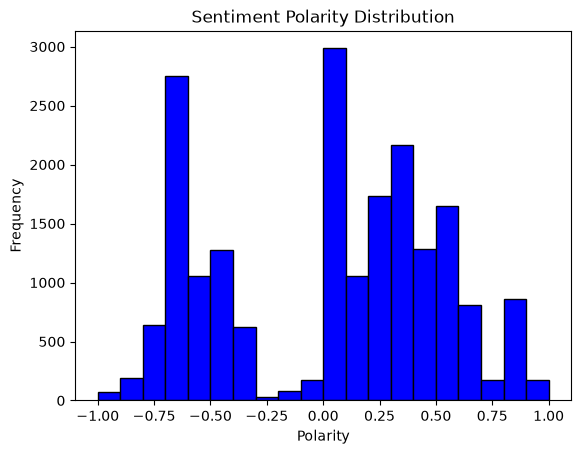

In [14]:
# Plot histogram
plt.hist(df['polarity'], bins=20, color='blue', edgecolor='black')
plt.title('Sentiment Polarity Distribution')
plt.xlabel('Polarity')
plt.ylabel('Frequency')
plt.show()

## **<center><u>Assessment: Experimentations (using Machine Learning)</u></center>**


In [15]:
# Vectorization
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['cleaned_comments'])

In [16]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, df['sentiment'], test_size=0.2, random_state=42)

In [17]:
print("Features X_train:")
X_train

Features X_train:


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 449135 stored elements and shape (15818, 45287)>

In [18]:
print("Features X_test:")
X_test

Features X_test:


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 114996 stored elements and shape (3955, 45287)>

In [19]:
print("Features y_train:")
y_train

Features y_train:


4832     negative
1336     negative
1402     negative
113      negative
18533    positive
           ...   
11284     neutral
11964     neutral
5390     negative
860      negative
15795    positive
Name: sentiment, Length: 15818, dtype: str

In [20]:
print("Features y_test:")
y_test

Features y_test:


8703      neutral
10633     neutral
7917      neutral
6415     negative
15185    positive
           ...   
13597    positive
9525      neutral
7048      neutral
8550      neutral
4847     negative
Name: sentiment, Length: 3955, dtype: str

# 1. Logistic Regression


In [21]:
print("Evaluation for: Logistic Regression Classifier".center(80, '_'))

lgc = LogisticRegression()
lgc.fit(X_train, y_train)

lgc_pred = lgc.predict(X_test)
lgc_acc = accuracy_score(y_test, lgc_pred)
lgc_prec = precision_score(y_test, lgc_pred, average='weighted')
lgc_rec = recall_score(y_test, lgc_pred, average='weighted')
lgc_f1 = f1_score(y_test, lgc_pred, average='weighted')

print(f"Model Type: {lgc}")
print("\n" + f"Prediciton: {lgc_pred}")
print('-' * 80)

print(f"Accuracy Score:  {(lgc_acc):%}")
print(f"Precision Score: {(lgc_prec):%}")
print(f"Recall Score:    {(lgc_rec):%}")
print(f"F1-Score:        {(lgc_f1):%}")

_________________Evaluation for: Logistic Regression Classifier_________________


Model Type: LogisticRegression()

Prediciton: ['positive' 'neutral' 'neutral' ... 'neutral' 'neutral' 'negative']
--------------------------------------------------------------------------------
Accuracy Score:  88.520860%
Precision Score: 88.568085%
Recall Score:    88.520860%
F1-Score:        88.471660%


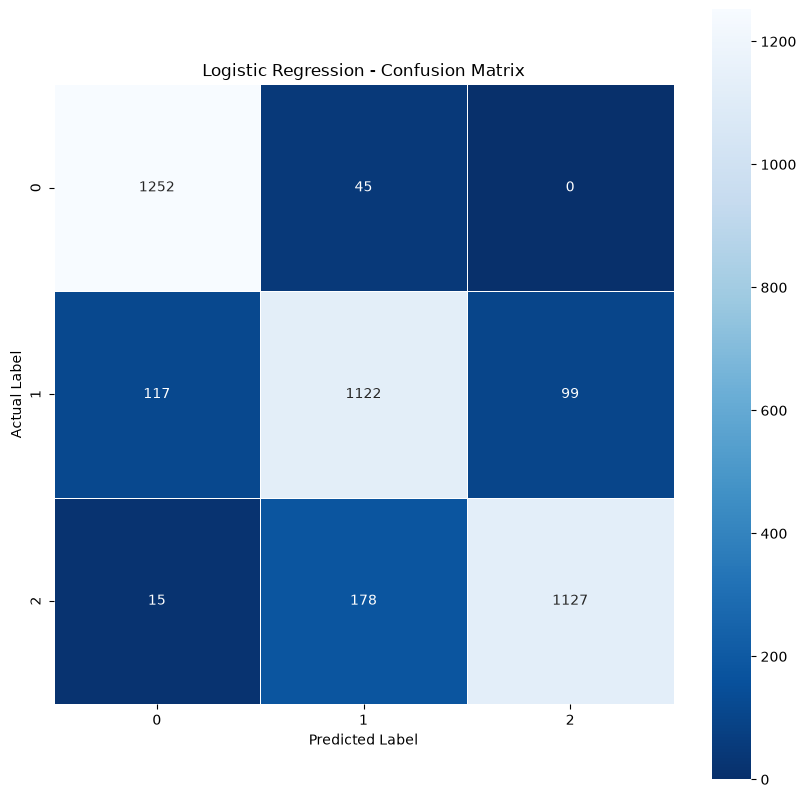

In [22]:
# Plotting the Confusion Matrix:
lgc_confusion_matrix = confusion_matrix(y_test, lgc_pred)

plt.figure(figsize=(10, 10))
sns.heatmap(lgc_confusion_matrix, annot=True, fmt=".0f",
            linewidths=0.7, square=True, cmap="Blues_r")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [23]:
print("Classification Report For Logistic Regression:")
print('-' * 57)
print(classification_report(y_test, lgc_pred))

Classification Report For Logistic Regression:
---------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.90      0.97      0.93      1297
     neutral       0.83      0.84      0.84      1338
    positive       0.92      0.85      0.89      1320

    accuracy                           0.89      3955
   macro avg       0.89      0.89      0.89      3955
weighted avg       0.89      0.89      0.88      3955



In [24]:
# Not saved to disk: this notebook trains and evaluates all 7 classifiers for comparison, but per the project's models-scope decision, only the TF-IDF vectorizer and the winning Gradient Boosting model (below) are committed — the dashboard only needs those two, and every model's metrics are already captured in this notebook's own printed output.

In [25]:
# save the vectorizer
joblib.dump(vectorizer, '../models/tfidf_vectorizer.pkl')

['../models/tfidf_vectorizer.pkl']

# 2. AdaBoost Classifier


In [26]:
print("Evaluation for: AdaBoost Classifier".center(57, '_'))

abc = AdaBoostClassifier()

abc.fit(X_train, y_train)

abc_prediction = abc.predict(X_test)
abc_accuracy_score = accuracy_score(y_test, abc_prediction)
abc_precision_score = precision_score(
    y_test, abc_prediction, average="weighted")
abc_recall_score = recall_score(y_test, abc_prediction, average="weighted")
abc_f1_score = f1_score(y_test, abc_prediction, average="weighted")

print(f"Model Type: {abc}")
print(f"Prediciton: {abc_prediction}")
print('-' * 57)

print(f"Accuracy Score:  {(abc_accuracy_score):%}")
print(f"Precision Score: {(abc_precision_score):%}")
print(f"Recall Score:    {(abc_recall_score):%}")
print(f"F1-Score:        {(abc_f1_score):%}")

___________Evaluation for: AdaBoost Classifier___________


Model Type: AdaBoostClassifier()
Prediciton: ['positive' 'neutral' 'neutral' ... 'neutral' 'neutral' 'negative']
---------------------------------------------------------
Accuracy Score:  75.145386%
Precision Score: 78.449406%
Recall Score:    75.145386%
F1-Score:        75.865758%


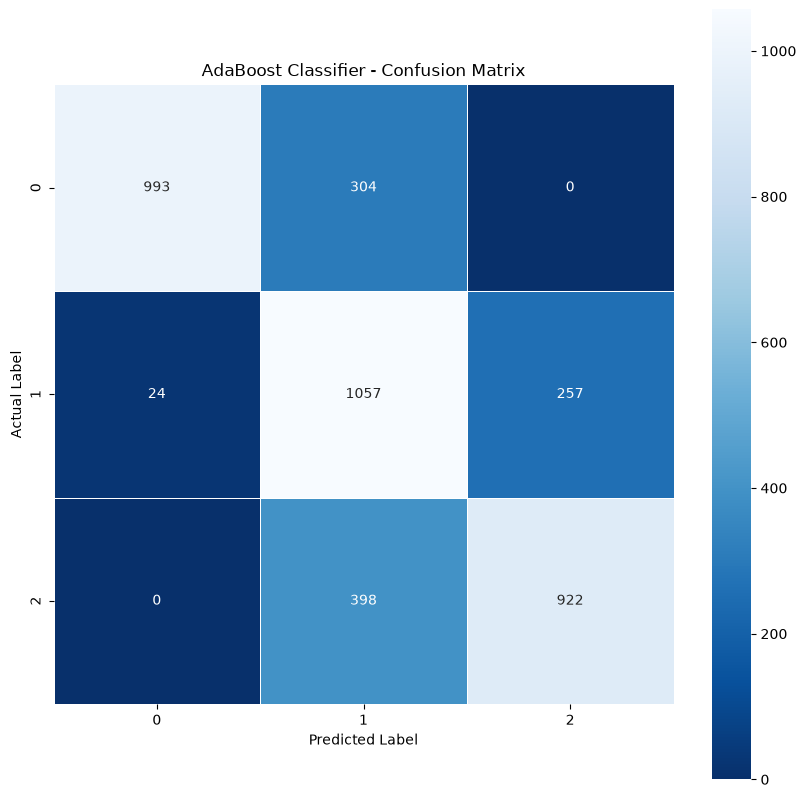

In [27]:
# Plotting the Confusion Matrix:
abc_confusion_matrix = confusion_matrix(y_test, abc_prediction)

plt.figure(figsize=(10, 10))
sns.heatmap(abc_confusion_matrix, annot=True, fmt=".0f",
            linewidths=0.7, square=True, cmap="Blues_r")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.title("AdaBoost Classifier - Confusion Matrix")
plt.show()

In [28]:
print("Classification Report For AdaBoost Classifier:")
print('-' * 57)
print(classification_report(y_test, abc_prediction))

Classification Report For AdaBoost Classifier:
---------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.98      0.77      0.86      1297
     neutral       0.60      0.79      0.68      1338
    positive       0.78      0.70      0.74      1320

    accuracy                           0.75      3955
   macro avg       0.79      0.75      0.76      3955
weighted avg       0.78      0.75      0.76      3955



In [29]:
# Not saved to disk: this notebook trains and evaluates all 7 classifiers for comparison, but per the project's models-scope decision, only the TF-IDF vectorizer and the winning Gradient Boosting model (below) are committed — the dashboard only needs those two, and every model's metrics are already captured in this notebook's own printed output.

# 3. K-Nearest Neighbors


In [30]:
print("Evaluation for: K-Neighbors Classifier".center(57, '_'))

knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

knn_prediction = knn.predict(X_test)
knn_accuracy_score = accuracy_score(y_test, knn_prediction)
knn_precision_score = precision_score(
    y_test, knn_prediction, average="weighted")
knn_recall_score = recall_score(y_test, knn_prediction, average="weighted")
knn_f1_score = f1_score(y_test, knn_prediction, average="weighted")

print(f"Model Type: {knn}")
print(f"Prediciton: {knn_prediction}")
print('-' * 57)

print(f"Accuracy Score:  {(knn_accuracy_score):%}")
print(f"Precision Score: {(knn_precision_score):%}")
print(f"Recall Score:    {(knn_recall_score):%}")
print(f"F1-Score:        {(knn_f1_score):%}")

__________Evaluation for: K-Neighbors Classifier_________


Model Type: KNeighborsClassifier()
Prediciton: ['neutral' 'neutral' 'neutral' ... 'neutral' 'neutral' 'neutral']
---------------------------------------------------------
Accuracy Score:  64.399494%
Precision Score: 70.524083%
Recall Score:    64.399494%
F1-Score:        64.974454%


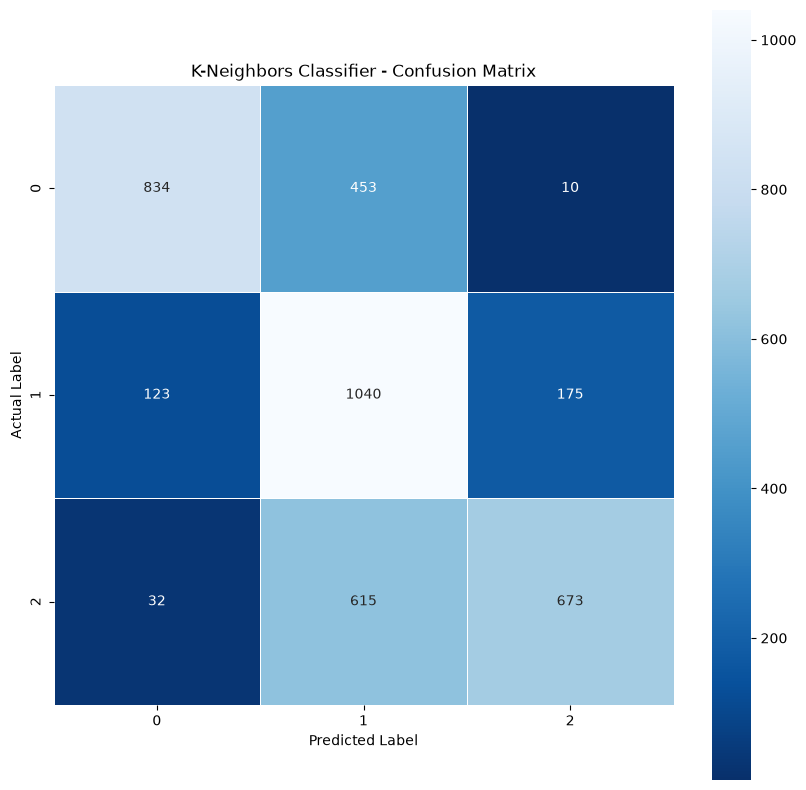

In [31]:
# Plotting the Confusion Matrix:
knn_confusion_matrix = confusion_matrix(y_test, knn_prediction)

plt.figure(figsize=(10, 10))
sns.heatmap(knn_confusion_matrix, annot=True, fmt=".0f",
            linewidths=0.7, square=True, cmap="Blues_r")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.title("K-Neighbors Classifier - Confusion Matrix")
plt.show()

In [32]:
print("Classification Report For K-Neighbors Classifier:")
print('-' * 57)
print(classification_report(y_test, knn_prediction))

Classification Report For K-Neighbors Classifier:
---------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.84      0.64      0.73      1297
     neutral       0.49      0.78      0.60      1338
    positive       0.78      0.51      0.62      1320

    accuracy                           0.64      3955
   macro avg       0.71      0.64      0.65      3955
weighted avg       0.71      0.64      0.65      3955



In [33]:
# Not saved to disk: this notebook trains and evaluates all 7 classifiers for comparison, but per the project's models-scope decision, only the TF-IDF vectorizer and the winning Gradient Boosting model (below) are committed — the dashboard only needs those two, and every model's metrics are already captured in this notebook's own printed output.

# 4. Decision Tree Classifier


In [34]:
print("Evaluation for: Decision Tree Classifier".center(57, '_'))

dtc = DecisionTreeClassifier()

dtc.fit(X_train, y_train)

dtc_prediction = dtc.predict(X_test)
dtc_accuracy_score = accuracy_score(y_test, dtc_prediction)
dtc_precision_score = precision_score(
    y_test, dtc_prediction, average="weighted")
dtc_recall_score = recall_score(y_test, dtc_prediction, average="weighted")
dtc_f1_score = f1_score(y_test, dtc_prediction, average="weighted")

print(f"Model Type: {dtc}")
print(f"Prediciton: {dtc_prediction}")
print('-' * 57)

print(f"Accuracy Score:  {(dtc_accuracy_score):%}")
print(f"Precision Score: {(dtc_precision_score):%}")
print(f"Recall Score:    {(dtc_recall_score):%}")
print(f"F1-Score:        {(dtc_f1_score):%}")

_________Evaluation for: Decision Tree Classifier________


Model Type: DecisionTreeClassifier()
Prediciton: ['neutral' 'neutral' 'neutral' ... 'neutral' 'neutral' 'negative']
---------------------------------------------------------
Accuracy Score:  87.155499%
Precision Score: 87.126259%
Recall Score:    87.155499%
F1-Score:        87.119818%


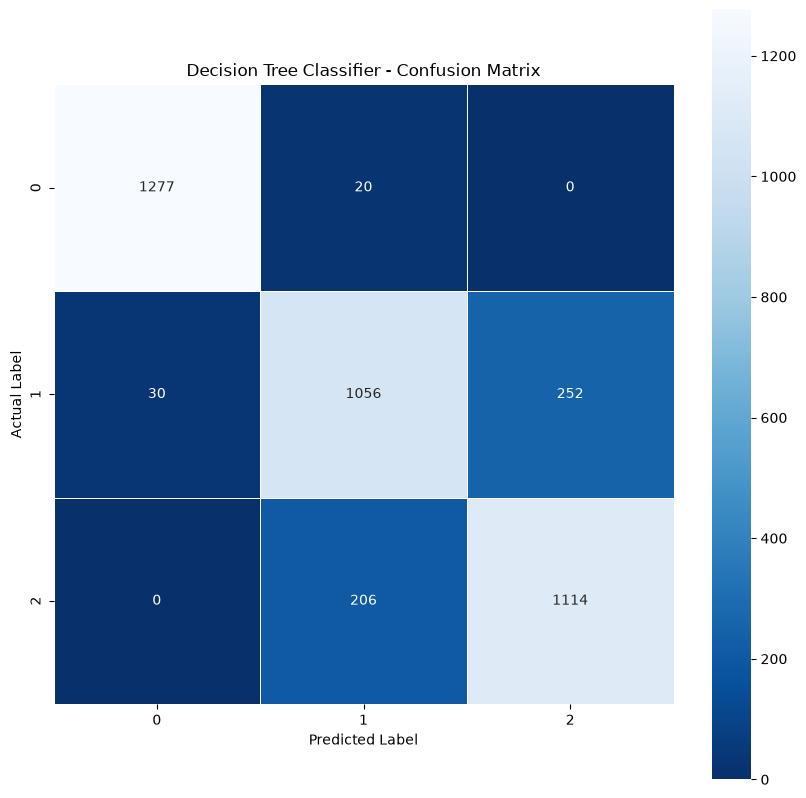

In [35]:
# Plotting the Confusion Matrix:
dtc_confusion_matrix = confusion_matrix(y_test, dtc_prediction)

plt.figure(figsize=(10, 10))
sns.heatmap(dtc_confusion_matrix, annot=True, fmt=".0f",
            linewidths=0.7, square=True, cmap="Blues_r")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.title("Decision Tree Classifier - Confusion Matrix")
plt.show()

In [36]:
print("Classification Report For Decision Tree Classifier:")
print('-' * 57)
print(classification_report(y_test, dtc_prediction))

Classification Report For Decision Tree Classifier:
---------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.98      0.98      0.98      1297
     neutral       0.82      0.79      0.81      1338
    positive       0.82      0.84      0.83      1320

    accuracy                           0.87      3955
   macro avg       0.87      0.87      0.87      3955
weighted avg       0.87      0.87      0.87      3955



In [37]:
# Not saved to disk: this notebook trains and evaluates all 7 classifiers for comparison, but per the project's models-scope decision, only the TF-IDF vectorizer and the winning Gradient Boosting model (below) are committed — the dashboard only needs those two, and every model's metrics are already captured in this notebook's own printed output.

# 5. Random Forest Classifier


In [38]:
print("Evaluation for: Random Forest Classifier".center(57, '_'))

rfc = RandomForestClassifier()

rfc.fit(X_train, y_train)

rfc_prediction = rfc.predict(X_test)
rfc_accuracy_score = accuracy_score(y_test, rfc_prediction)
rfc_precision_score = precision_score(
    y_test, rfc_prediction, average="weighted")
rfc_recall_score = recall_score(y_test, rfc_prediction, average="weighted")
rfc_f1_score = f1_score(y_test, rfc_prediction, average="weighted")

print(f"Model Type: {rfc}")
print(f"Prediciton: {rfc_prediction}")
print('-' * 57)

print(f"Accuracy Score:  {(rfc_accuracy_score):%}")
print(f"Precision Score: {(rfc_precision_score):%}")
print(f"Recall Score:    {(rfc_recall_score):%}")
print(f"F1-Score:        {(rfc_f1_score):%}")

_________Evaluation for: Random Forest Classifier________


Model Type: RandomForestClassifier()
Prediciton: ['positive' 'neutral' 'neutral' ... 'neutral' 'neutral' 'negative']
---------------------------------------------------------
Accuracy Score:  83.388116%
Precision Score: 83.370911%
Recall Score:    83.388116%
F1-Score:        82.976612%


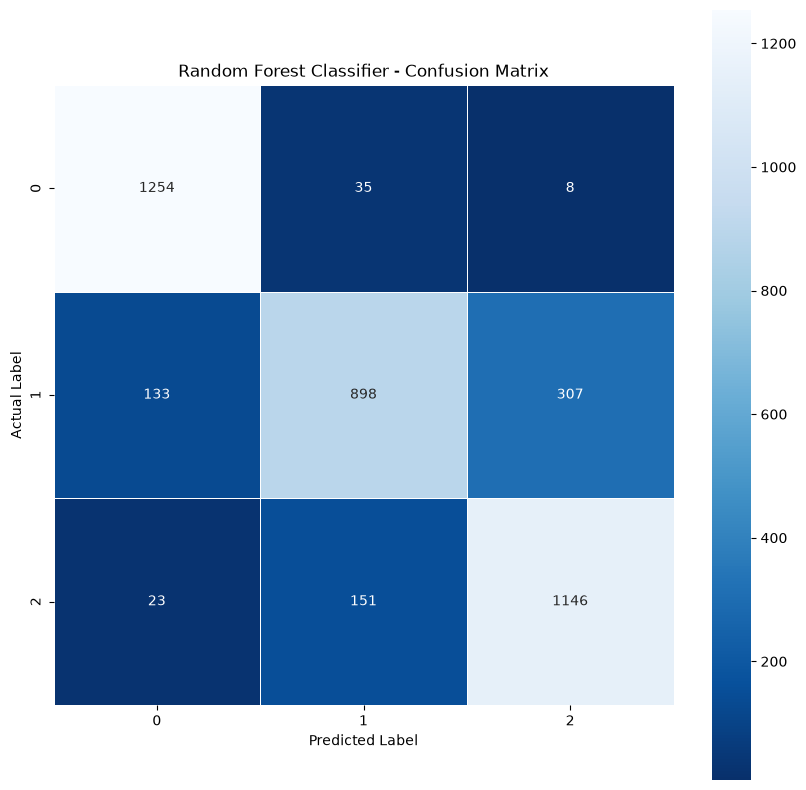

In [39]:
# Plotting the Confusion Matrix:
rfc_confusion_matrix = confusion_matrix(y_test, rfc_prediction)

plt.figure(figsize=(10, 10))
sns.heatmap(rfc_confusion_matrix, annot=True, fmt=".0f",
            linewidths=0.7, square=True, cmap="Blues_r")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.title("Random Forest Classifier - Confusion Matrix")
plt.show()

In [40]:
print("Classification Report For Random Forest Classifier:")
print('-' * 57)
print(classification_report(y_test, rfc_prediction))

Classification Report For Random Forest Classifier:
---------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.89      0.97      0.93      1297
     neutral       0.83      0.67      0.74      1338
    positive       0.78      0.87      0.82      1320

    accuracy                           0.83      3955
   macro avg       0.83      0.84      0.83      3955
weighted avg       0.83      0.83      0.83      3955



In [41]:
# Not saved to disk: this notebook trains and evaluates all 7 classifiers for comparison, but per the project's models-scope decision, only the TF-IDF vectorizer and the winning Gradient Boosting model (below) are committed — the dashboard only needs those two, and every model's metrics are already captured in this notebook's own printed output.

# 6. Gradient Boosting Classifier


In [42]:
print("Evaluation for: Gradient Boosting Classifier".center(57, '_'))

gbc = GradientBoostingClassifier()

gbc.fit(X_train, y_train)

gbc_prediction = gbc.predict(X_test)
gbc_accuracy_score = accuracy_score(y_test, gbc_prediction)
gbc_precision_score = precision_score(
    y_test, gbc_prediction, average="weighted")
gbc_recall_score = recall_score(y_test, gbc_prediction, average="weighted")
gbc_f1_score = f1_score(y_test, gbc_prediction, average="weighted")

print(f"Model Type: {gbc}")
print(f"Prediciton: {gbc_prediction}")
print('-' * 57)

print(f"Accuracy Score:  {(gbc_accuracy_score):%}")
print(f"Precision Score: {(gbc_precision_score):%}")
print(f"Recall Score:    {(gbc_recall_score):%}")
print(f"F1-Score:        {(gbc_f1_score):%}")

_______Evaluation for: Gradient Boosting Classifier______


Model Type: GradientBoostingClassifier()
Prediciton: ['positive' 'neutral' 'neutral' ... 'neutral' 'neutral' 'negative']
---------------------------------------------------------
Accuracy Score:  89.886220%
Precision Score: 90.023113%
Recall Score:    89.886220%
F1-Score:        89.929756%


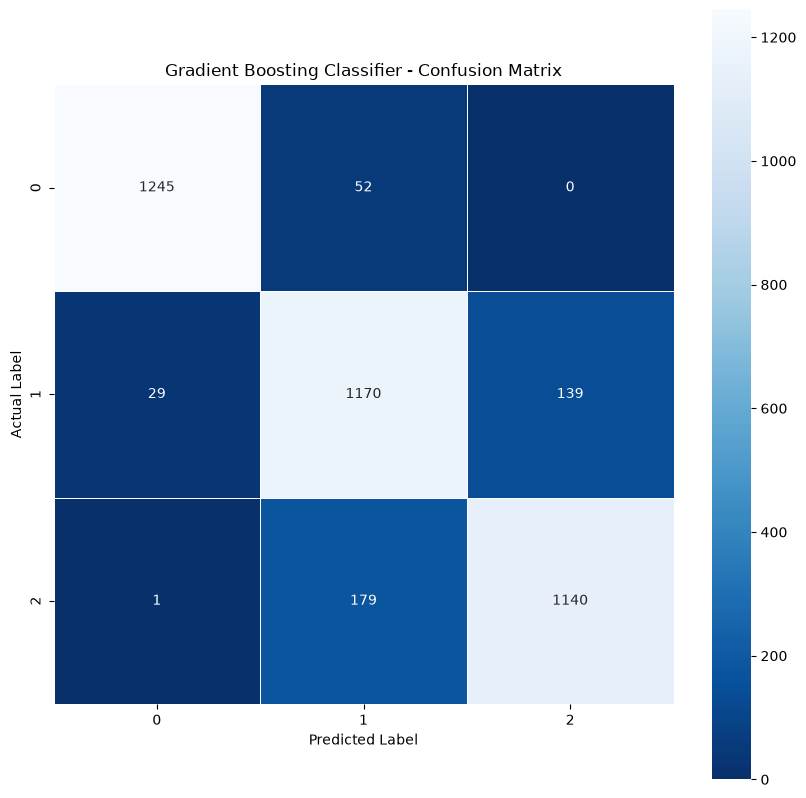

In [43]:
# Plotting the Confusion Matrix:
gbc_confusion_matrix = confusion_matrix(y_test, gbc_prediction)

plt.figure(figsize=(10, 10))
sns.heatmap(gbc_confusion_matrix, annot=True, fmt=".0f",
            linewidths=0.7, square=True, cmap="Blues_r")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.title("Gradient Boosting Classifier - Confusion Matrix")
plt.show()

In [44]:
print("Classification Report For Gradient Boosting Classifier:")
print('-' * 57)
print(classification_report(y_test, gbc_prediction))

Classification Report For Gradient Boosting Classifier:
---------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.98      0.96      0.97      1297
     neutral       0.84      0.87      0.85      1338
    positive       0.89      0.86      0.88      1320

    accuracy                           0.90      3955
   macro avg       0.90      0.90      0.90      3955
weighted avg       0.90      0.90      0.90      3955



In [45]:
# save the gradient boosting model (the dashboard's live predictor uses this one)
joblib.dump(gbc, '../models/gradient_boosting_model.pkl')

['../models/gradient_boosting_model.pkl']

# 7. C-Support Vector Classifier


In [46]:
print("Evaluation for: C-Support Vector Classification".center(57, '_'))

svc = SVC()

svc.fit(X_train, y_train)

svc_prediction = svc.predict(X_test)
svc_accuracy_score = accuracy_score(y_test, svc_prediction)
svc_precision_score = precision_score(
    y_test, svc_prediction, average="weighted")
svc_recall_score = recall_score(y_test, svc_prediction, average="weighted")
svc_f1_score = f1_score(y_test, svc_prediction, average="weighted")

print(f"Model Type: {svc}")
print(f"Prediciton: {svc_prediction}")
print('-' * 57)

print(f"Accuracy Score:  {(svc_accuracy_score):%}")
print(f"Precision Score: {(svc_precision_score):%}")
print(f"Recall Score:    {(svc_recall_score):%}")
print(f"F1-Score:        {(svc_f1_score):%}")

_____Evaluation for: C-Support Vector Classification_____


Model Type: SVC()
Prediciton: ['positive' 'neutral' 'neutral' ... 'neutral' 'neutral' 'negative']
---------------------------------------------------------
Accuracy Score:  88.192162%
Precision Score: 88.281568%
Recall Score:    88.192162%
F1-Score:        88.137227%


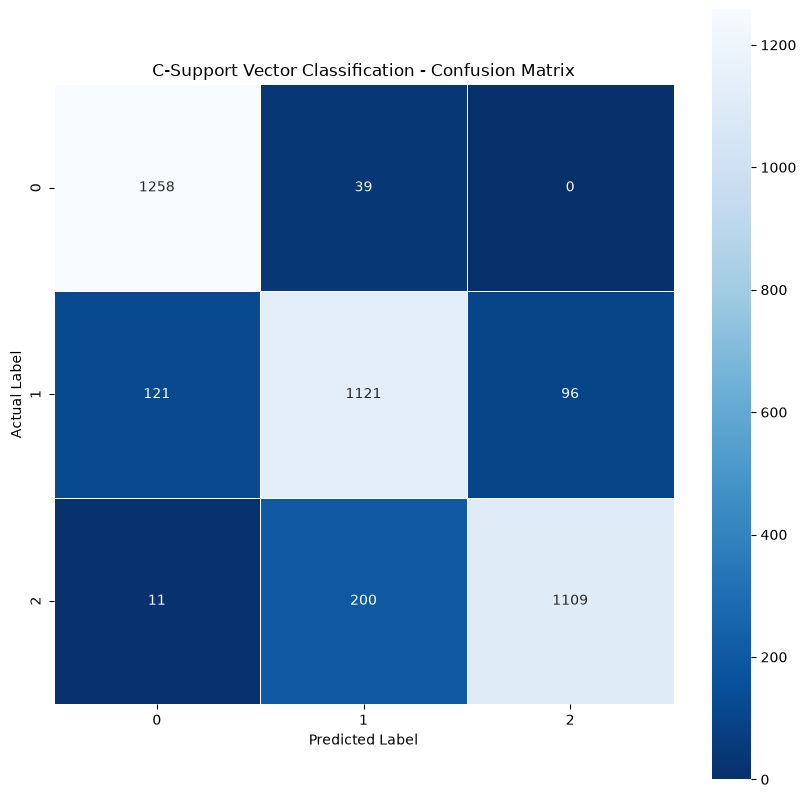

In [47]:
# Plotting the Confusion Matrix:
svc_confusion_matrix = confusion_matrix(y_test, svc_prediction)

plt.figure(figsize=(10, 10))
sns.heatmap(svc_confusion_matrix, annot=True, fmt=".0f",
            linewidths=0.7, square=True, cmap="Blues_r")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.title("C-Support Vector Classification - Confusion Matrix")
plt.show()

In [48]:
print("Classification Report For C-Support Vector Classification:")
print('-' * 63)
print(classification_report(y_test, svc_prediction))

Classification Report For C-Support Vector Classification:
---------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.91      0.97      0.94      1297
     neutral       0.82      0.84      0.83      1338
    positive       0.92      0.84      0.88      1320

    accuracy                           0.88      3955
   macro avg       0.88      0.88      0.88      3955
weighted avg       0.88      0.88      0.88      3955



In [49]:
# Not saved to disk: this notebook trains and evaluates all 7 classifiers for comparison, but per the project's models-scope decision, only the TF-IDF vectorizer and the winning Gradient Boosting model (below) are committed — the dashboard only needs those two, and every model's metrics are already captured in this notebook's own printed output.

## <center><u>Visualising the Metric Scores for all Classifier Models</u></center>


In [50]:
lgc_scores = [lgc_acc*100, lgc_prec*100, lgc_rec*100, lgc_f1*100]
abc_scores = [abc_accuracy_score*100, abc_precision_score*100,
              abc_recall_score*100, abc_f1_score*100]
knn_scores = [knn_accuracy_score*100, knn_precision_score*100,
              knn_recall_score*100, knn_f1_score*100]
dtc_scores = [dtc_accuracy_score*100, dtc_precision_score*100,
              dtc_recall_score*100, dtc_f1_score*100]
rfc_scores = [rfc_accuracy_score*100, rfc_precision_score*100,
              rfc_recall_score*100, rfc_f1_score*100]
gbc_scores = [gbc_accuracy_score*100, gbc_precision_score*100,
              gbc_recall_score*100, gbc_f1_score*100]
svc_scores = [svc_accuracy_score*100, svc_precision_score*100,
              svc_recall_score*100, svc_f1_score*100]

x_grid = ["Accuracy", "Precision", "Recall", "F1-Score"]
y_grid = [value for value in range(1, 120, 10)]
xpos = np.arange(len(x_grid))
bar_width = .10

plt.figure(figsize=(20, 10), dpi=700, facecolor='w', edgecolor='k')
plt.title("Model Evaluation Scores", fontsize=20)
# Function to add value labels on the bars


def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, height,
                 f'{height:.2f}%', ha='center', va='bottom', rotation=90)


# Create bars and add labels
bars_lgc = plt.bar(xpos, lgc_scores, width=bar_width,
                   label="Logistic Regression")
add_labels(bars_lgc)

bars_abc = plt.bar(xpos + bar_width, abc_scores,
                   width=bar_width, label="AdaBoost")
add_labels(bars_abc)

bars_knn = plt.bar(xpos + bar_width*2, knn_scores,
                   width=bar_width, label="K-Neighbors")
add_labels(bars_knn)

bars_dtc = plt.bar(xpos + bar_width*3, dtc_scores,
                   width=bar_width, label="Decision Tree")
add_labels(bars_dtc)

bars_rfc = plt.bar(xpos + bar_width*4, rfc_scores,
                   width=bar_width, label="Random Forest")
add_labels(bars_rfc)

bars_gbc = plt.bar(xpos + bar_width*5, gbc_scores,
                   width=bar_width, label="Gradient Boosting")
add_labels(bars_gbc)

bars_svc = plt.bar(xpos + bar_width*6, svc_scores,
                   width=bar_width, label="C-Support Vector")
add_labels(bars_svc)

plt.xticks(xpos + bar_width*3, x_grid, fontsize=15)
plt.yticks(y_grid, fontsize=15)
plt.xlabel("Evaluation Metrics", fontsize=20)
plt.ylabel("Percentage", fontsize=20)
plt.legend(bbox_to_anchor=(1.15, 1), borderaxespad=0.)
plt.show()